In [ ]:
import xarray as xr
from matplotlib import pyplot as plt

In [ ]:
ds_true = xr.open_mfdataset(["/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_35.nc", "/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_36.nc"])

/tmp/ipykernel_410162/3110944369.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_true = xr.open_mfdataset(["/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_35.nc", "/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_36.nc"])


In [ ]:
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2025-11-25_15-34-17/predictions.nc")
ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2025-11-25_16-24-30/predictions.nc")

In [ ]:
ds_pred

<xarray.Dataset> Size: 373MB
Dimensions:               (time: 290, nSCHISM_hgrid_node: 311243)
Coordinates:
  * time                  (time) datetime64[ns] 2kB 2020-02-04T00:05:00 ... 2...
  * nSCHISM_hgrid_node    (nSCHISM_hgrid_node) int64 2MB 0 1 2 ... 311241 311242
    SCHISM_hgrid_node_x   (nSCHISM_hgrid_node) float64 2MB ...
    SCHISM_hgrid_node_y   (nSCHISM_hgrid_node) float64 2MB ...
    nSCHISM_hgrid_node_x  (nSCHISM_hgrid_node) float64 2MB ...
    nSCHISM_hgrid_node_y  (nSCHISM_hgrid_node) float64 2MB ...
Data variables:
    sigWaveHeight         (time, nSCHISM_hgrid_node) float32 361MB ...
Attributes:
    description:  Predictions for sigWaveHeight
    checkpoint:   /work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/...
    model:        src.model.WWMEmulator.WWMEmulator

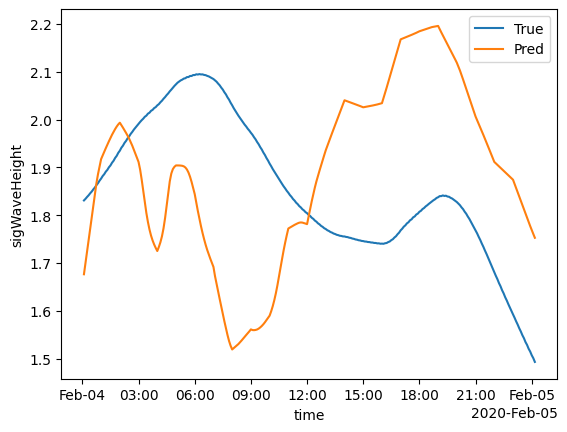

In [ ]:
ds_true["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot(label="True")
ds_pred["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot(label="Pred")
plt.legend()

In [ ]:
import pyvista as pv
import numpy as np

# Create 3D points (PyVista requires 3D coordinates)
points = np.column_stack([x, y, np.zeros_like(x)])

x = ds_true.SCHISM_hgrid_node_x.values
y = ds_true.SCHISM_hgrid_node_y.values


In [ ]:
def fc_to_pyv(ix):
    # Convert face connectivity to PyVista format
    face_node_connectivity = ds_true.isel(time=ix).SCHISM_hgrid_face_nodes.values

    # Handle both triangular (NaN in 4th column) and quad faces
    faces = []
    for face_nodes in face_node_connectivity:
        if np.isnan(face_nodes[3]):
            # Triangular face
            faces.append(3)  # number of points
            faces.extend(face_nodes[:3].astype(int))
        else:
            # Quadrilateral face
            faces.append(4)  # number of points
            faces.extend(face_nodes.astype(int))

    faces = np.array(faces, dtype=int)
    return faces

def plot_feature_map(ix, features):
    faces = fc_to_pyv(ix)

    # meshes
    meshes = [pv.PolyData(points, faces) for _ in range(len(features))]
    for feature, mesh in zip(features, meshes):
        mesh["z"] = ds_true.isel(time=ix)[feature].values

    plotter = pv.Plotter(border=True, shape=(1, len(features)), window_size=(400*len(features), 400))

    for i, feat, mesh in zip(range(len(meshes)), features, meshes):
        plotter.subplot(0, i)
        plotter.add_text(feat, font_size=14)
        plotter.add_mesh(mesh, scalars="z", cmap="viridis", show_edges=False, scalar_bar_args={"title": feat})
        plotter.view_xy()
        plotter.enable_parallel_projection()

    plotter.show()

def plot_target_bias_map(ix, target):
    
    faces = fc_to_pyv(ix)
    # Create the mesh
    mesh_true = pv.PolyData(points, faces)
    mesh_pred = pv.PolyData(points, faces)
    mesh_bias = pv.PolyData(points, faces)

    mesh_true["z"] = ds_true.isel(time=ix)[target].values
    mesh_pred["z"] = ds_pred.isel(time=ix)[target].values
    mesh_bias["z"] = ds_pred.isel(time=ix)[target].values - ds_true.isel(time=ix)[target].values

    vmax = max(mesh_true["z"].max(), mesh_pred["z"].max())

    # Visualize
    # Create plotter with 2D view
    plotter = pv.Plotter(border=True, shape=(1, 3), window_size=(1200, 400))

    # -- true --
    plotter.subplot(0, 0)
    plotter.add_text("True", font_size=14)
    plotter.add_mesh(mesh_true, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"True {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- pred --
    plotter.subplot(0, 1)
    plotter.add_text("Pred", font_size=14)
    plotter.add_mesh(mesh_pred, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"Pred {target}"})
    #plotter.add_scalar_bar(title='Predicted sigWaveHeight [m]')
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- bias --
    plotter.subplot(0, 2)
    plotter.add_text("Bias", font_size=14)
    plotter.add_mesh(mesh_bias, scalars='z', cmap='RdBu_r', clim=(-vmax, +vmax), show_edges=False, scalar_bar_args={"title": f"Bias {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection


    plotter.show()

In [ ]:
ds_true

<xarray.Dataset> Size: 23GB
Dimensions:                  (time: 290, one: 1, nSCHISM_hgrid_node: 311243,
                              nSCHISM_hgrid_face: 611503,
                              nMaxSCHISM_hgrid_face_nodes: 4,
                              nSCHISM_hgrid_edge: 922875, two: 2)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2020-02-04T00:05:00 .....
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float64 2MB dask.array<chunksize=(311243,), meta=np.ndarray>
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float64 2MB dask.array<chunksize=(311243,), meta=np.ndarray>
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float64 5MB dask.array<chunksize=(611503,), meta=np.ndarray>
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float64 5MB dask.array<chunksize=(611503,), meta=np.ndarray>
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float64 7MB dask.array<chunksize=(922875,), meta=np.ndarray>
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float64 7MB dask.array<chunksize=(922875,), meta=np.ndarray>
Dimensions without coordinates: one, nSCHISM_hgrid_node, nSCHISM_hgrid_face,
                                nMaxSCHISM_hgrid_face_nodes,
                                nSCHISM_hgrid_edge, two
Data variables: (12/37)
    minimum_depth            (time, one) float64 2kB dask.array<chunksize=(288, 1), meta=np.ndarray>
    SCHISM_hgrid             (time, one) |S1 290B dask.array<chunksize=(288, 1), meta=np.ndarray>
    depth                    (time, nSCHISM_hgrid_node) float32 361MB dask.array<chunksize=(288, 311243), meta=np.ndarray>
    bottom_index_node        (time, nSCHISM_hgrid_node) int32 361MB dask.array<chunksize=(288, 311243), meta=np.ndarray>
    SCHISM_hgrid_face_nodes  (time, nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes) float64 6GB dask.array<chunksize=(288, 611503, 4), meta=np.ndarray>
    SCHISM_hgrid_edge_nodes  (time, nSCHISM_hgrid_edge, two) float64 4GB dask.array<chunksize=(288, 922875, 2), meta=np.ndarray>
    ...                       ...
    dominantDirection        (time, nSCHISM_hgrid_node) float32 361MB dask.array<chunksize=(1, 311243), meta=np.ndarray>
    peakSpreading            (time, nSCHISM_hgrid_node) float32 361MB dask.array<chunksize=(1, 311243), meta=np.ndarray>
    discretePeakDirectio     (time, nSCHISM_hgrid_node) float32 361MB dask.array<chunksize=(1, 311243), meta=np.ndarray>
    orbitalVelocity          (time, nSCHISM_hgrid_node) float32 361MB dask.array<chunksize=(1, 311243), meta=np.ndarray>
    dryFlagElement           (time, nSCHISM_hgrid_face) float32 709MB dask.array<chunksize=(1, 611503), meta=np.ndarray>
    dryFlagSide              (time, nSCHISM_hgrid_edge) float32 1GB dask.array<chunksize=(1, 922875), meta=np.ndarray>

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


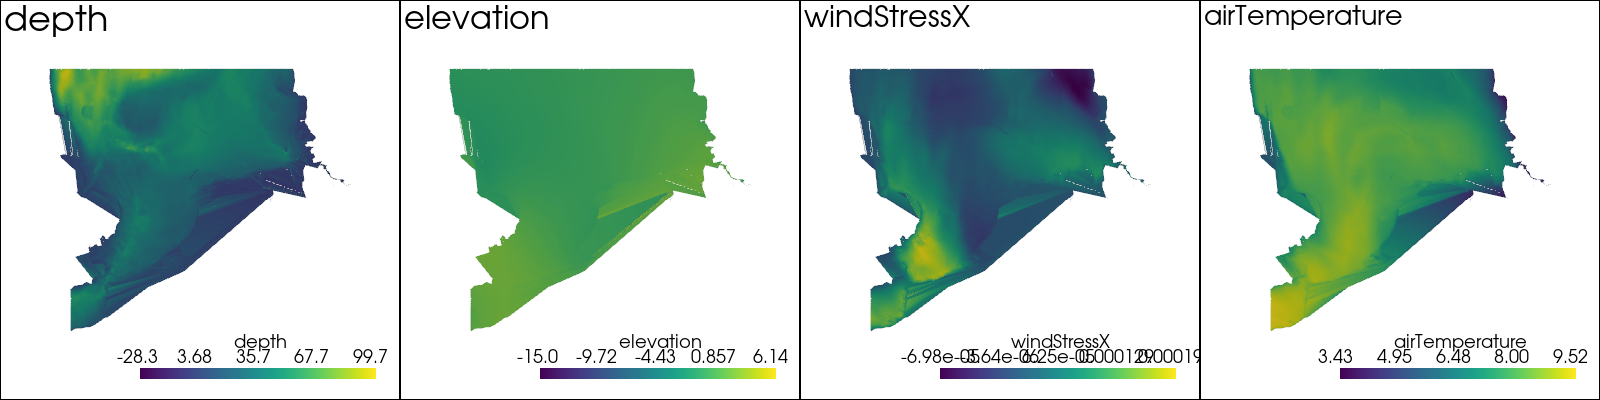

In [ ]:
plot_feature_map(229, ["depth", "elevation", "windStressX", "airTemperature"])

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


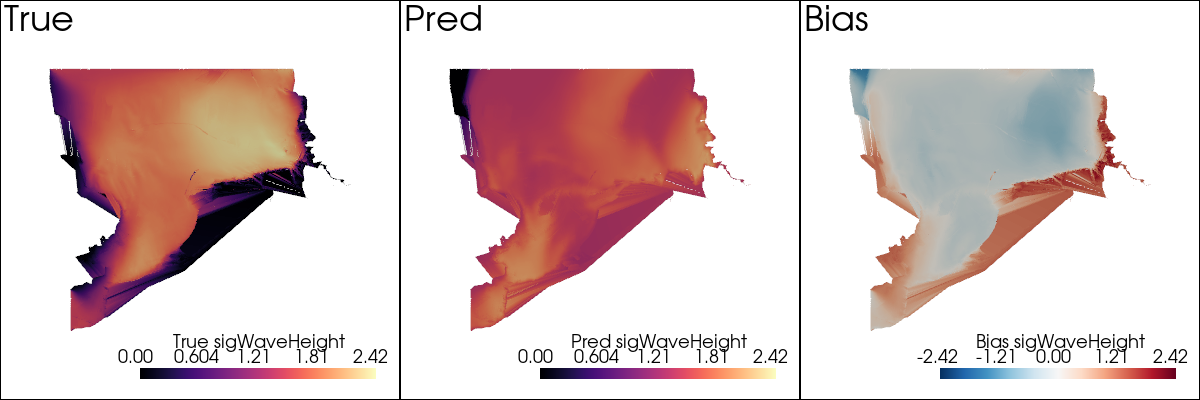

In [ ]:
plot_target_bias_map(289, "sigWaveHeight")

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


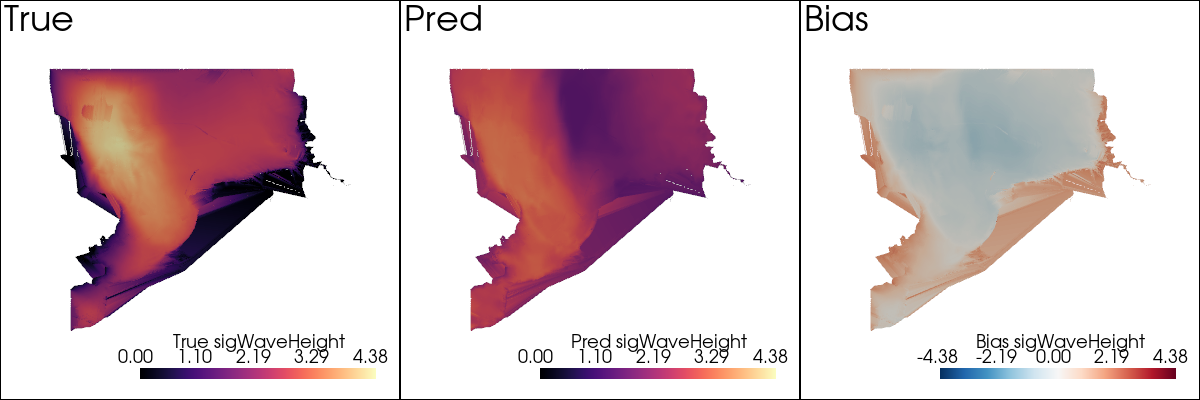

In [ ]:
plot_target_bias_map(165, "sigWaveHeight")

In [ ]:
node_ix = [210369, 212863, 214076]

/tmp/ipykernel_410162/3424881046.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


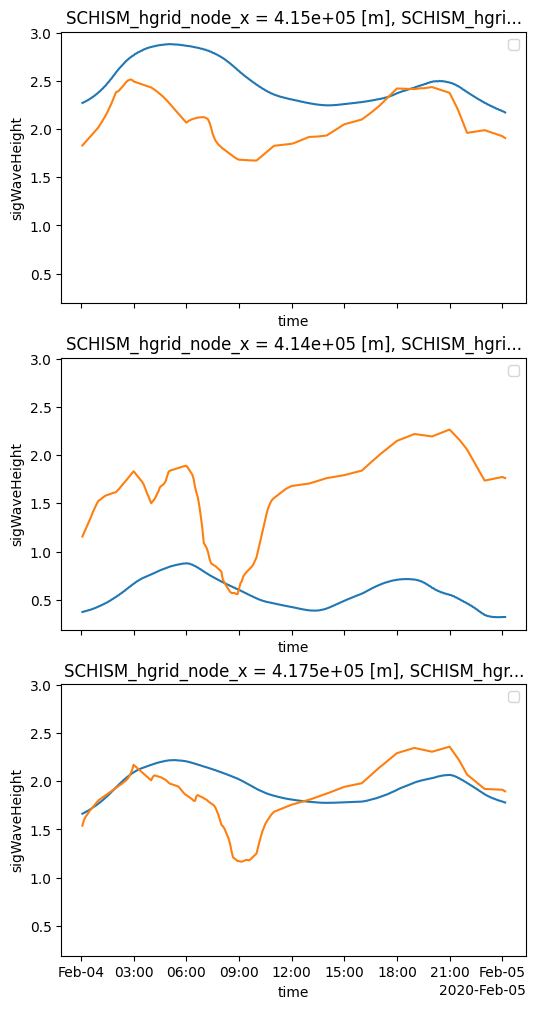

In [ ]:
fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(6, 12))

for ix, ax in zip(node_ix, axs):
    ds_true.isel(nSCHISM_hgrid_node=ix)["sigWaveHeight"].plot(ax=ax)
    ds_pred.isel(nSCHISM_hgrid_node=ix)["sigWaveHeight"].plot(ax=ax)
    ax.legend()